In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## hyperparameter-surface

**Figure 4: Validation loss over a 13 × 13 sweep of learning rate and weight decay.** Both axes are log-spaced; contour lines are labelled with the loss, and the circle marks the lowest loss. The loss is lowest, 1.91, at learning rate 3.2e-4 and weight decay 5.6e-3, and climbs steeply as training diverges at the largest learning rates, up to 4.55 at 1e-2.

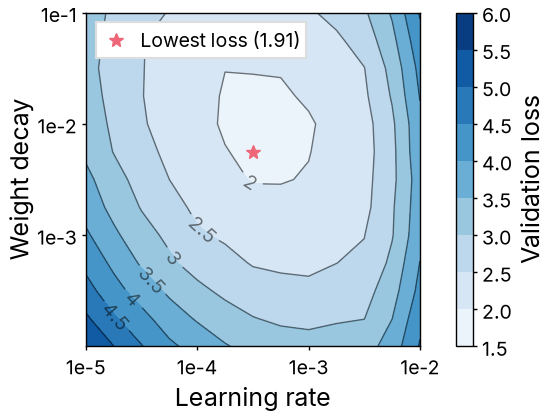

In [2]:
from matplotlib import rcParams

data = json.load(open("../data/hyperparameter-surface.json"))
# contoured in log10 coordinates: clabel's inline gaps come out wrong on log-scaled axes
log_lr = np.log10(data["learning_rate"])
log_wd = np.log10(data["weight_decay"])
val_loss = np.array(data["val_loss"])
best_i, best_j = np.unravel_index(val_loss.argmin(), val_loss.shape)

fig, ax = plt.subplots(figsize=(2.75, 2.75))
cs = ax.contourf(log_lr, log_wd, val_loss, levels=8)
lines = ax.contour(log_lr, log_wd, val_loss, levels=cs.levels, colors="black", alpha=0.5)
# one label per level, along the diagonal toward the lower-left corner where the lines are spread out
label_positions = [(-3.5, -2.5), (-3.95, -2.95), (-4.2, -3.2), (-4.4, -3.4), (-4.57, -3.57), (-4.72, -3.72)]
ax.clabel(lines, fmt="%.2g", manual=label_positions)
fig.colorbar(cs, ax=ax, label="Validation loss")
ax.plot(log_lr[best_j], log_wd[best_i], "*", color=colors["ours"], markerfacecolor=colors["ours"], markersize=2 * rcParams["lines.markersize"], linestyle="none", label=f"Lowest loss ({val_loss[best_i, best_j]:.3g})")
ax.set_xticks([-5, -4, -3, -2], labels=["1e-5", "1e-4", "1e-3", "1e-2"])
ax.set_yticks([-3, -2, -1], labels=["1e-3", "1e-2", "1e-1"])
ax.set_xlabel("Learning rate")
ax.set_ylabel("Weight decay")
ax.grid(False)
ax.legend(loc="upper left")
fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/hyperparameter-surface.pdf")
fig.savefig("../outputs/hyperparameter-surface.png")
plt.show()